# Design 3: the treatments I didn't get (prototype)

Static matplotlib prototype. Graves disease is usually treated one of three ways: antithyroid pills
(what I take, methimazole), radioactive iodine, or surgery. Kaggle flags patients who had each one,
so we can see where their TSH ended up and put my own results on pills next to them.

- Kaggle data: `data/thyroidDF.csv`. Treatment groups come from the `on_antithyroid_meds`,
  `I131_treatment` and `thyroid_surgery` flags. A few patients have two flags (7 in total) and count in
  both groups. Patients without a TSH result are left out, and ages over 100 are typos and dropped.
- Kaggle doesn't record why someone had iodine or surgery, so not every patient here had Graves.
- My data: `data/personal_thyroid.csv`, every draw where I was taking methimazole (dose above 0).
  The Kaggle bars count patients, one result each; my bar counts my own results over time.
- TSH bands use the typical adult range, 0.4 to 4.0 mIU/L, the same one Joel's population notebook uses.
  Low TSH means the thyroid is still overactive; high TSH means it's underactive.
- Right panel: share of each group also taking thyroxine, the replacement hormone for an underactive thyroid.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("..") / "data"
TSH_RANGE = (0.4, 4.0)
TREATMENTS = {
    "on_antithyroid_meds": "Antithyroid pills",
    "I131_treatment": "Radioactive iodine",
    "thyroid_surgery": "Surgery",
}
BANDS = ["low", "normal", "high"]

kaggle = pd.read_csv(DATA / "thyroidDF.csv",
                     usecols=["age", "TSH", "on_thyroxine"] + list(TREATMENTS))
kaggle = kaggle[kaggle["age"] <= 100].dropna(subset=["TSH"])

personal = pd.read_csv(DATA / "personal_thyroid.csv", usecols=["date", "TSH", "methimazole_mg", "on_thyroxine"])
on_pills = personal.dropna(subset=["TSH"])
on_pills = on_pills[on_pills["methimazole_mg"] > 0]


def band(tsh):
    return pd.cut(tsh, [0, TSH_RANGE[0], TSH_RANGE[1], np.inf], labels=BANDS, right=False)


rows = []
for flag, name in TREATMENTS.items():
    s = kaggle[kaggle[flag] == "t"]
    shares = band(s["TSH"]).value_counts(normalize=True).reindex(BANDS)
    rows.append({"name": f"Kaggle: {name.lower()}", "n": f"{len(s)} patients", **shares,
                 "thyroxine": (s["on_thyroxine"] == "t").mean()})
shares = band(on_pills["TSH"]).value_counts(normalize=True).reindex(BANDS)
rows.append({"name": "Me: methimazole", "n": f"{len(on_pills)} of my results", **shares,
             "thyroxine": (on_pills["on_thyroxine"] == "t").mean()})
table = pd.DataFrame(rows)
table

,name,n,low,normal,high,thyroxine
0,Kaggle: antithyroid pills,108 patients,0.472222,0.324074,0.203704,0.111111
1,Kaggle: radioactive iodine,166 patients,0.331325,0.433735,0.234940,0.319277
2,Kaggle: surgery,128 patients,0.250000,0.484375,0.265625,0.195312
3,Me: methimazole,15 of my results,0.466667,0.400000,0.133333,0.000000


## The plot

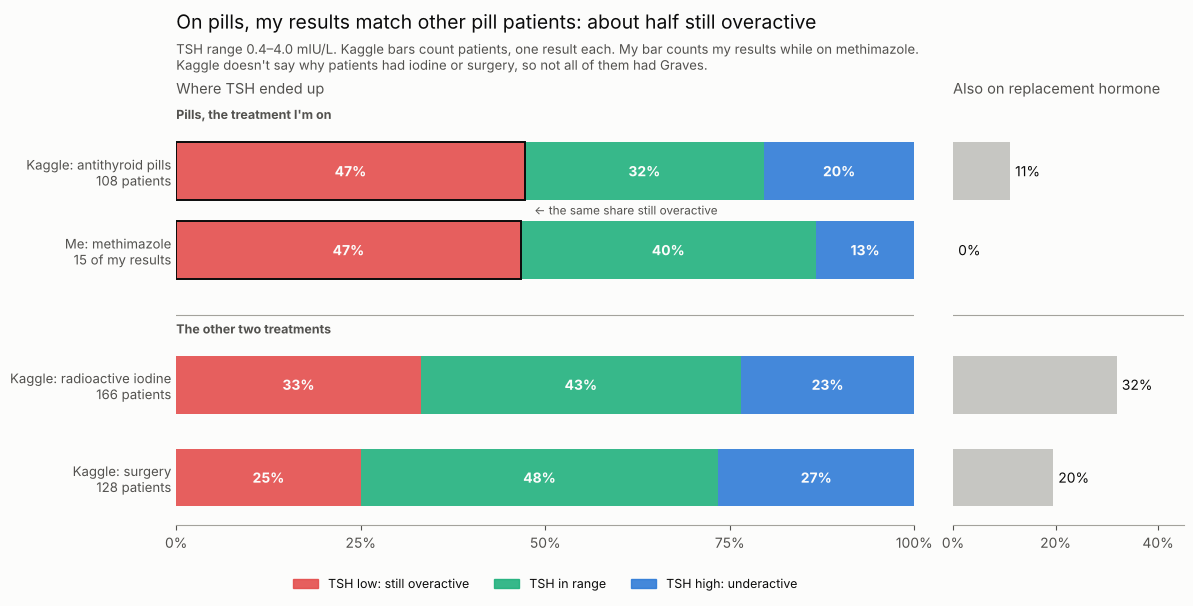

In [2]:
BAND_COLORS = {"low": "#e34948", "normal": "#1baf7a", "high": "#2a78d6"}
BAND_LABELS = {"low": "TSH low: still overactive", "normal": "TSH in range", "high": "TSH high: underactive"}
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#a3a29c"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Rows: Kaggle pills, iodine, surgery, me. My row goes right under the pills row so they can be compared,
# and the two other treatments sit below a divider.
y = np.array([3.5, 1.2, 0.2, 2.65])
fig, (ax, ax_t) = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True,
                               gridspec_kw={"width_ratios": [3.2, 1], "wspace": 0.08})

left = np.zeros(len(table))
for b in BANDS:
    ax.barh(y, table[b], left=left, height=0.62, color=BAND_COLORS[b], alpha=0.88, lw=0, zorder=2)
    for yi, l, v in zip(y, left, table[b]):
        ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=10, fontweight="bold",
                color=SURFACE, zorder=3)
    left += table[b].to_numpy()

# Outline the "still overactive" share in the two pill rows.
for i in (0, 3):
    ax.barh(y[i], table.loc[i, "low"], height=0.62, fill=False, edgecolor=INK, lw=1.4, zorder=4)
ax.text(0.485, 3.08, "← the same share still overactive", ha="left", va="center", fontsize=8.5, color=INK2)
ax.text(0, 1.72, "The other two treatments", fontsize=9, color=INK2, fontweight="bold", va="bottom")
ax.text(0, 4.03, "Pills, the treatment I'm on", fontsize=9, color=INK2, fontweight="bold", va="bottom")

ax.axhline(1.95, color=MUTED, lw=0.8)
ax_t.axhline(1.95, color=MUTED, lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([f"{r['name']}\n{r['n']}" for _, r in table.iterrows()], fontsize=9.5)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 1)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.spines["left"].set_visible(False)
ax.set_title("Where TSH ended up", loc="left", fontsize=10.5, color=INK2, pad=22)
handles = [plt.Rectangle((0, 0), 1, 1, color=BAND_COLORS[b], alpha=0.88) for b in BANDS]
ax.legend(handles, [BAND_LABELS[b] for b in BANDS], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3,
          frameon=False, fontsize=9)

ax_t.barh(y, table["thyroxine"], height=0.62, color=MUTED, alpha=0.6, lw=0)
for yi, v in zip(y, table["thyroxine"]):
    ax_t.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=10, color=INK)
ax_t.set_xlim(0, 0.45)
ax_t.set_xticks([0, 0.2, 0.4])
ax_t.set_xticklabels(["0%", "20%", "40%"])
ax_t.tick_params(axis="y", length=0)
ax_t.spines["left"].set_visible(False)
ax_t.set_title("Also on replacement hormone", loc="left", fontsize=10.5, color=INK2, pad=22)

fig.suptitle("On pills, my results match other pill patients: about half still overactive",
             x=0.125, y=1.1, ha="left", fontsize=14)
fig.text(0.125, 1.04, f"TSH range {TSH_RANGE[0]}–{TSH_RANGE[1]} mIU/L. Kaggle bars count patients, one result "
         "each. My bar counts my results while on methimazole.\nKaggle doesn't say why patients had iodine or "
         "surgery, so not all of them had Graves.", fontsize=9.5, color=INK2, va="top")
fig.savefig("treatments.png", dpi=110, bbox_inches="tight")
plt.show()